<a href="https://colab.research.google.com/github/mrmcgruder98/Assignment-2-PDS/blob/main/Assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 25)

local_path = Path("data/Ass2 PDS.csv")
data_url = "https://github.com/mrmcgruder98/Assignment-2-PDS/raw/refs/heads/main/Ass2%20PDS.csv"
source = local_path if local_path.exists() else data_url

# Ensure output directory exists if loading locally in the future
if not local_path.exists():
    local_path.parent.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_csv(source)
print(f"Dataset successfully loaded from: {source}")
print(f"Dataset Shape: {df_raw.shape}")

Dataset successfully loaded from: https://github.com/mrmcgruder98/Assignment-2-PDS/raw/refs/heads/main/Ass2%20PDS.csv
Dataset Shape: (5847, 14)


### 1. Identify and Visualize Missing Values
We take the given information to highlight the missing values.

,Missing Count,Percentage (%)
New_Price,5032,86.061228
Seats,38,0.649906
Power,36,0.615700
Engine,36,0.615700
Mileage,2,0.034206
Unnamed: 0,0,0.000000
Fuel_Type,0,0.000000
Kilometers_Driven,0,0.000000
Year,0,0.000000
Location,0,0.000000


/tmp/ipykernel_816/1571724582.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_df['Missing Count'], y=missing_df.index, palette='viridis')


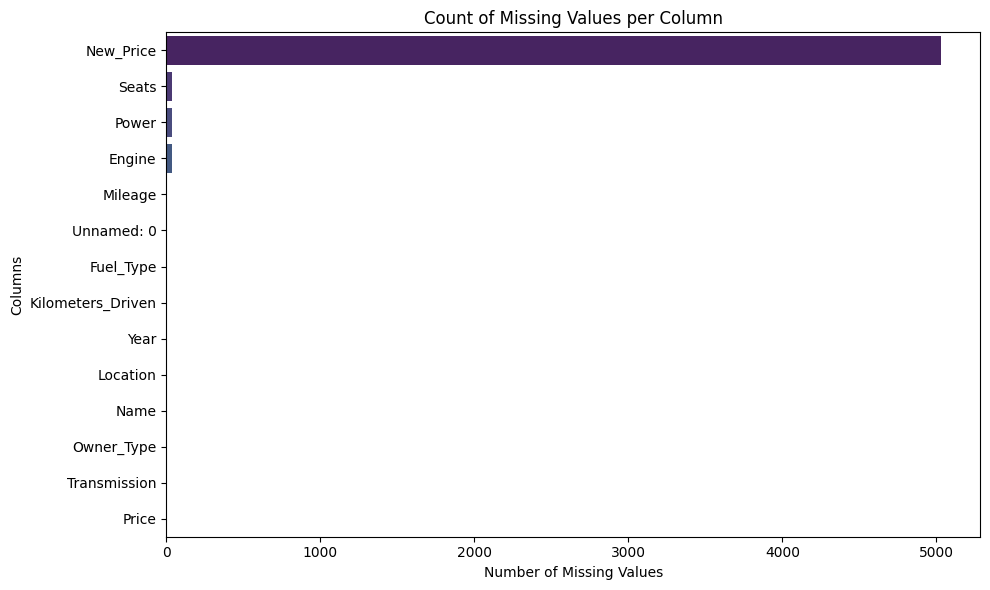

In [2]:
# Identify missing values
missing_counts = df_raw.isnull().sum()
missing_percentages = (df_raw.isnull().sum() / len(df_raw)) * 100

missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage (%)': missing_percentages
}).sort_values(by='Missing Count', ascending=False)

display(missing_df)

# Visualize missing values
plt.figure(figsize=(10, 6))
sns.barplot(x=missing_df['Missing Count'], y=missing_df.index, palette='viridis')
plt.title('Count of Missing Values per Column')
plt.xlabel('Number of Missing Values')
plt.ylabel('Columns')
plt.tight_layout()
plt.show()

### 2. Replace Missing Values with Column Mean
Now, we will impute the missing values in numerical columns using their mean.

In [3]:
# Create a copy of the dataframe to keep the raw data intact
df_cleaned = df_raw.copy()

# Select only numerical columns for mean imputation
numerical_cols = df_cleaned.select_dtypes(include=[np.number]).columns

# Fill missing values in numerical columns with their mean
for col in numerical_cols:
    if df_cleaned[col].isnull().any():
        mean_val = df_cleaned[col].mean()
        df_cleaned[col] = df_cleaned[col].fillna(mean_val)
        print(f"Imputed {col} missing values with mean: {mean_val:.4f}")

# Verify that there are no remaining missing values in numerical columns
remaining_missing = df_cleaned[numerical_cols].isnull().sum()
print("\nRemaining missing values in numerical columns:")
print(remaining_missing)

Imputed Seats missing values with mean: 5.2865

Remaining missing values in numerical columns:
Unnamed: 0           0
Year                 0
Kilometers_Driven    0
Seats                0
Price                0
dtype: int64


### 3. Clean Text Units and Convert to Numeric
Several columns like `Mileage`, `Engine`, and `Power` contain numeric values appended with units (e.g., "19.67 kmpl", "1198 CC", "88.7 bhp"). We need to strip these units, convert the columns to floats, and then recalculate/impute their missing values.

In [4]:
import re

def clean_and_convert(val):
    if pd.isna(val):
        return np.nan
    # Cast to string, strip whitespace, and extract the first numeric group
    val_str = str(val).strip()
    # Handle cases where value might be 'null' as a string
    if val_str.lower() == 'null':
        return np.nan
    match = re.match(r'([0-9.]+)', val_str)
    if match:
        return float(match.group(1))
    return np.nan

# Clean columns: Mileage, Engine, Power
cols_to_clean = ['Mileage', 'Engine', 'Power']
for col in cols_to_clean:
    if col in df_cleaned.columns:
        df_cleaned[col] = df_cleaned[col].apply(clean_and_convert)
        # Impute newly converted column with its mean
        col_mean = df_cleaned[col].mean()
        df_cleaned[col] = df_cleaned[col].fillna(col_mean)
        print(f"Cleaned {col}: removed units and imputed remaining missing with mean {col_mean:.4f}")

# Verify updated columns and null counts
display(df_cleaned[cols_to_clean].info())
display(df_cleaned[cols_to_clean].head())

Cleaned Mileage: removed units and imputed remaining missing with mean 18.1585
Cleaned Engine: removed units and imputed remaining missing with mean 1631.5526
Cleaned Power: removed units and imputed remaining missing with mean 113.8031
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5847 entries, 0 to 5846
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Mileage  5847 non-null   float64
 1   Engine   5847 non-null   float64
 2   Power    5847 non-null   float64
dtypes: float64(3)
memory usage: 137.2 KB


None

,Mileage,Engine,Power
0,19.67,1582.0,126.20
1,13.00,1199.0,88.70
2,20.77,1248.0,88.76
3,15.20,1968.0,140.80
4,23.08,1461.0,63.10


### 4. One-Hot Encoding Categorical Variables
We will now convert the categorical variables `Fuel_Type` and `Transmission` into numerical one-hot encoded features.

In [5]:
# Perform one-hot encoding on 'Fuel_Type' and 'Transmission'
df_encoded = pd.get_dummies(df_cleaned, columns=['Fuel_Type', 'Transmission'], dtype=int)

# Display the newly created one-hot encoded columns along with a few others
encoded_cols = [col for col in df_encoded.columns if 'Fuel_Type_' in col or 'Transmission_' in col]
display(df_encoded[['Name'] + encoded_cols].head())

,Name,Fuel_Type_Diesel,Fuel_Type_Electric,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual
0,Hyundai Creta 1.6 CRDi SX Option,1,0,0,0,1
1,Honda Jazz V,0,0,1,0,1
2,Maruti Ertiga VDI,1,0,0,0,1
3,Audi A4 New 2.0 TDI Multitronic,1,0,0,1,0
4,Nissan Micra Diesel XV,1,0,0,0,1


### 5. Extract and Categorize Vehicle Brand
We will extract the first word from the `Name` column to represent the brand of each vehicle.

In [8]:
# Extract the brand (first word) from the Name column
df_encoded['Brand'] = df_encoded['Name'].str.split().str[0]

# Display the unique brands and a preview of the new column
print(f"Unique brands found: {df_encoded['Brand'].nunique()}")
display(df_encoded[['Brand', 'Name']].head())


Unique brands found: 30


,Brand,Name
0,Hyundai,Hyundai Creta 1.6 CRDi SX Option
1,Honda,Honda Jazz V
2,Maruti,Maruti Ertiga VDI
3,Audi,Audi A4 New 2.0 TDI Multitronic
4,Nissan,Nissan Micra Diesel XV


### 6. Filter Dataset for Honda Vehicles
Let's filter the dataset to display only the vehicles with the brand **Honda**.

In [9]:
# Filter the dataframe for rows where the Brand is 'Honda'
honda_vehicles = df_encoded[df_encoded['Brand'] == 'Honda']

# Display the shape and the first few rows of the filtered dataset
print(f"Number of Honda vehicles found: {honda_vehicles.shape[0]}")
display(honda_vehicles.head())

Number of Honda vehicles found: 607


,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price,Fuel_Type_Diesel,Fuel_Type_Electric,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual,Brand
1,2,Honda Jazz V,Chennai,2011,46000,First,13.0,1199.0,88.7,5.0,8.61 Lakh,4.50,0,0,1,0,1,Honda
9,11,Honda City 1.5 V AT Sunroof,Kolkata,2012,60000,First,16.8,1497.0,116.3,5.0,NaN,4.49,0,0,1,1,0,Honda
14,16,Honda Amaze S i-Dtech,Kochi,2016,58950,First,25.8,1498.0,98.6,5.0,NaN,5.40,1,0,0,0,1,Honda
23,25,Honda City Corporate Edition,Mumbai,2012,51920,First,16.8,1497.0,116.3,5.0,NaN,4.25,0,0,1,0,1,Honda
26,28,Honda WRV i-VTEC VX,Kochi,2018,37430,First,17.5,1199.0,88.7,5.0,10.57 Lakh,9.90,0,0,1,0,1,Honda


###Reference:

https://www.google.com/search?q=example+of+viridis+plot+code+example+python&sca_esv=42aa4b2de3049085&biw=1920&bih=951&sxsrf=AKL5yDjT5NHvuRhPN8ThC5tC8YwmyhQITQ%3A1794879841114&ei=YbH7aqLGBrafqtsPyPfJ2QQ&oq=example+of+viridis+plot+code+example+&gs_lp=Egxnd3Mtd2l6LXNlcnAiJWV4YW1wbGUgb2YgdmlyaWRpcyBwbG90IGNvZGUgZXhhbXBsZSAqBQgBGKABMgUQIRigATIFECEYoAEyBRAhGKABSMoQUM8BWM8BcAF4AZABAJgBeaABeaoBAzAuMbgBAcgBAPgBAZgCAqAChQHCAgoQABhHGNYEGLADwgIOEAAY5AIY1gQYsAPYAQHCAhcQLhjcBhi4BhjaBhjYAhjIAxiwA9gBAZgDAIgGAZAGDroGBggBEAEYCZIHAzEuMaAH0QOyBwMwLjG4B37CBwMyLTLIBwiACAE&sclient=gws-wiz-serp

